In [1]:
import sys
print(sys.executable)

/Users/srilu/RudrakshSyal/Work/VistaDPE/dynamic_pricing_engine/.venv/bin/python


In [2]:
# !uv add polars plotly statsmodels matplotlib scikit-learn lightgbm prophet
# !uv run jupyter lab
# !uv run python -m ipykernel install --user --name=dynamic-pricing # or if already in jupyter:
# then select "dynamic-pricing" kernel in Jupyter

# This does three things simultaneously:
# 1. Installs the package into .venv
# 2. Adds it to pyproject.toml under [dependencies]
# 3. Updates uv.lock with exact pinned versions

# Imports
import polars as pl
import polars.selectors as cs

import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots

import statsmodels.api as sm
import numpy as np
from pathlib import Path

# Paths
DATA_RAW = Path("../data/raw/availability_data_2024_2025_2026.csv")

# Plotly defaults (standard settings for all plots)
PLOT_CFG = dict(
    width=1200, height=700,
    margin=dict(l=50, r=50, t=50, b=120),
    legend=dict(
        orientation="h", yanchor="top",
        y=-0.15, xanchor="center", x=0.5,
        font=dict(size=10)
    )
)

In [3]:
# Always run this one-liner first on any new file to see raw string values
print(pl.read_csv(DATA_RAW).head(3).select("DATE_DAY"))

shape: (3, 1)
┌────────────┐
│ DATE_DAY   │
│ ---        │
│ str        │
╞════════════╡
│ 2024-01-01 │
│ 2024-01-01 │
│ 2024-01-01 │
└────────────┘


In [4]:
df_raw = pl.read_csv(DATA_RAW, try_parse_dates=False)

df = (
    df_raw
    .with_columns(
        pl.col("DATE_DAY")
          .str.to_date(format="%Y-%m-%d")
          .alias("DATE_DAY")
    )
    .filter(
        pl.col("DATE_DAY").dt.year().is_in([2024, 2025])
    )
)

print(f"Shape: {df.shape}")
print(f"Date range: {df['DATE_DAY'].min()} → {df['DATE_DAY'].max()}")
print(f"\nFleet models: {df['FLEET_MODEL'].unique().to_list()}")
print(f"\nAIRCRAFT_DAILY_STATUS unique values:")
print(df['AIRCRAFT_DAILY_STATUS'].value_counts().sort('count', descending=True))

Shape: (31469, 17)
Date range: 2024-01-01 → 2025-12-31

Fleet models: ['Challenger 350', 'Challenger 300']

AIRCRAFT_DAILY_STATUS unique values:
shape: (7, 2)
┌─────────────────────────────────┬───────┐
│ AIRCRAFT_DAILY_STATUS           ┆ count │
│ ---                             ┆ ---   │
│ str                             ┆ u32   │
╞═════════════════════════════════╪═══════╡
│ Flown                           ┆ 18559 │
│ Maintenance - Unscheduled       ┆ 4343  │
│ Maintenance - Scheduled         ┆ 3400  │
│ Available                       ┆ 1765  │
│ Repositioning                   ┆ 1651  │
│ Maintenance - Aircraft on Grou… ┆ 1211  │
│ Crew Not Available              ┆ 540   │
└─────────────────────────────────┴───────┘


In [5]:
df_fleet = (
    df
    .group_by("DATE_DAY")
    .agg([
        pl.len().alias("num_tails"),
        pl.col("MAINTENANCE_AIRCRAFT_ON_GROUND_COUNT").sum().alias("aog_count"),
        pl.col("MAINTENANCE_SCHEDULED_COUNT").sum().alias("smx_count"),
        pl.col("MAINTENANCE_UNSCHEDULED_COUNT").sum().alias("umx_count"),
        pl.col("CREW_NOT_AVAILABLE_COUNT").sum().alias("cna_count"),
        pl.col("TOTAL_MAINTENANCE_COUNT").sum().alias("total_maint_count"),
        pl.col("DELIVERED_COUNT").sum().alias("delivered_count"),
    ])
    .sort("DATE_DAY")
    .with_columns([
        (pl.col("aog_count") / pl.col("num_tails")).alias("aog_rate"),
        (pl.col("smx_count") / pl.col("num_tails")).alias("smx_rate"),
        (pl.col("umx_count") / pl.col("num_tails")).alias("umx_rate"),
        (pl.col("cna_count") / pl.col("num_tails")).alias("cna_rate"),
        (pl.col("total_maint_count") / pl.col("num_tails")).alias("total_maint_rate"),
        (pl.col("delivered_count") / pl.col("num_tails")).alias("avail_rate"),
        pl.col("DATE_DAY").dt.weekday().alias("day_of_week"),
        pl.col("DATE_DAY").dt.month().alias("month"),
        pl.col("DATE_DAY").dt.quarter().alias("quarter"),
        pl.col("DATE_DAY").dt.ordinal_day().alias("day_of_year"),
        pl.col("DATE_DAY").dt.year().alias("year"),
    ])
)

# ── CORRECTED integrity check ─────────────────────────────────────────────
# All 5 buckets must sum to num_tails on every row
df_fleet = df_fleet.with_columns(
    (
        pl.col("delivered_count") +
        pl.col("aog_count") +
        pl.col("smx_count") +
        pl.col("umx_count") +
        pl.col("cna_count")
    ).alias("bucket_sum")
)

violations = df_fleet.filter(
    (pl.col("bucket_sum") - pl.col("num_tails")).abs() > 0
)
print(f"Integrity check violations: {len(violations)} (expect 0)")

# ── rate-level check: all 5 rates must sum to 1.0 ────────────────────────
df_fleet = df_fleet.with_columns(
    (
        pl.col("avail_rate") +
        pl.col("aog_rate") +
        pl.col("smx_rate") +
        pl.col("umx_rate") +
        pl.col("cna_rate")
    ).alias("rate_sum_check")
)
rate_violations = df_fleet.filter(
    (pl.col("rate_sum_check") - 1.0).abs() > 0.001
)
print(f"Rate sum violations: {len(rate_violations)} (expect 0)")

# ── clean up check columns before proceeding ─────────────────────────────
df_fleet = df_fleet.drop(["bucket_sum", "rate_sum_check"])

print(f"\nAggregated shape: {df_fleet.shape}")
print(f"\nSummary stats:")
print(df_fleet.select([
    "aog_rate","smx_rate","umx_rate","cna_rate","avail_rate"
]).describe())

Integrity check violations: 0 (expect 0)
Rate sum violations: 0 (expect 0)

Aggregated shape: (731, 19)

Summary stats:
shape: (9, 6)
┌────────────┬──────────┬──────────┬──────────┬──────────┬────────────┐
│ statistic  ┆ aog_rate ┆ smx_rate ┆ umx_rate ┆ cna_rate ┆ avail_rate │
│ ---        ┆ ---      ┆ ---      ┆ ---      ┆ ---      ┆ ---        │
│ str        ┆ f64      ┆ f64      ┆ f64      ┆ f64      ┆ f64        │
╞════════════╪══════════╪══════════╪══════════╪══════════╪════════════╡
│ count      ┆ 731.0    ┆ 731.0    ┆ 731.0    ┆ 731.0    ┆ 731.0      │
│ null_count ┆ 0.0      ┆ 0.0      ┆ 0.0      ┆ 0.0      ┆ 0.0        │
│ mean       ┆ 0.038503 ┆ 0.108028 ┆ 0.13804  ┆ 0.017162 ┆ 0.698267   │
│ std        ┆ 0.031043 ┆ 0.035481 ┆ 0.057845 ┆ 0.027328 ┆ 0.069611   │
│ min        ┆ 0.0      ┆ 0.023256 ┆ 0.0      ┆ 0.0      ┆ 0.488372   │
│ 25%        ┆ 0.023256 ┆ 0.093023 ┆ 0.093023 ┆ 0.0      ┆ 0.651163   │
│ 50%        ┆ 0.023256 ┆ 0.113636 ┆ 0.139535 ┆ 0.0      ┆ 0.697674   │
│ 

In [6]:
fig = go.Figure()

fig.add_trace(go.Scatter(
    x=df_fleet["DATE_DAY"].to_list(),
    y=df_fleet["num_tails"].to_list(),
    mode="lines",
    name="Total tails in fleet",
    line=dict(color="#2563eb", width=1.5)
))

fig.update_layout(
    title="Fleet Size (num_tails) Over Time — NREG US",
    xaxis_title="Date",
    yaxis_title="Number of Tails",
    **PLOT_CFG
)
fig.show()

In [7]:
rate_cols = ["aog_rate", "smx_rate", "umx_rate", "cna_rate"]
colors = ["#dc2626", "#2563eb", "#d97706", "#16a34a"]

fig = go.Figure()
for col, color in zip(rate_cols, colors):
    fig.add_trace(go.Scatter(
        x=df_fleet["DATE_DAY"].to_list(),
        y=df_fleet[col].to_list(),
        mode="lines",
        name=col.upper().replace("_RATE",""),
        line=dict(color=color, width=1),
        opacity=0.8
    ))

# also add 30-day rolling mean for each to see signal through noise
df_pd = df_fleet.to_pandas()  # statsmodels and rolling need pandas
for col, color in zip(rate_cols, colors):
    rolling = df_pd[col].rolling(30, center=True).mean()
    fig.add_trace(go.Scatter(
        x=df_pd["DATE_DAY"].tolist(),
        y=rolling.tolist(),
        mode="lines",
        name=f"{col.upper().replace('_RATE','')} (30d avg)",
        line=dict(color=color, width=2.5, dash="dash")
    ))

fig.update_layout(
    title="Maintenance Rates Over Time — NREG US (raw + 30-day rolling mean)",
    xaxis_title="Date",
    yaxis_title="Rate (fraction of fleet)",
    **PLOT_CFG
)
fig.show()

In [8]:
fig = make_subplots(rows=2, cols=2, subplot_titles=[
    "AOG Rate by Month", "SMX Rate by Month",
    "UMX Rate by Month", "CNA Rate by Month"
])

month_labels = ["Jan","Feb","Mar","Apr","May","Jun",
                "Jul","Aug","Sep","Oct","Nov","Dec"]

for idx, col in enumerate(rate_cols):
    row, col_pos = divmod(idx, 2)
    for month_num in range(1, 13):
        vals = df_pd[df_pd["month"] == month_num][col].dropna().tolist()
        fig.add_trace(
            go.Box(y=vals, name=month_labels[month_num-1],
                   showlegend=(idx == 0),
                   marker_color=colors[idx]),
            row=row+1, col=col_pos+1
        )

fig.update_layout(
    title="Monthly Seasonality of Maintenance Rates",
    height=900, width=1200,
    margin=dict(l=50, r=50, t=80, b=50),
    showlegend=False
)
fig.show()

In [9]:
dow_labels = ["Mon","Tue","Wed","Thu","Fri","Sat","Sun"]

fig = make_subplots(rows=2, cols=2, subplot_titles=[
    "AOG Rate by Day of Week", "SMX Rate by Day of Week",
    "UMX Rate by Day of Week", "CNA Rate by Day of Week"
])

for idx, col in enumerate(rate_cols):
    row, col_pos = divmod(idx, 2)
    means = df_pd.groupby("day_of_week")[col].mean().reindex(range(7))
    fig.add_trace(
        go.Bar(
            x=dow_labels,
            y=means.values,
            name=col,
            marker_color=colors[idx],
            showlegend=True
        ),
        row=row+1, col=col_pos+1
    )

fig.update_layout(
    title="Day-of-Week Effect on Maintenance Rates",
    height=900, width=1200,
    margin=dict(l=50, r=50, t=80, b=50),
    showlegend=False
)
fig.show()

Matplotlib is building the font cache; this may take a moment.


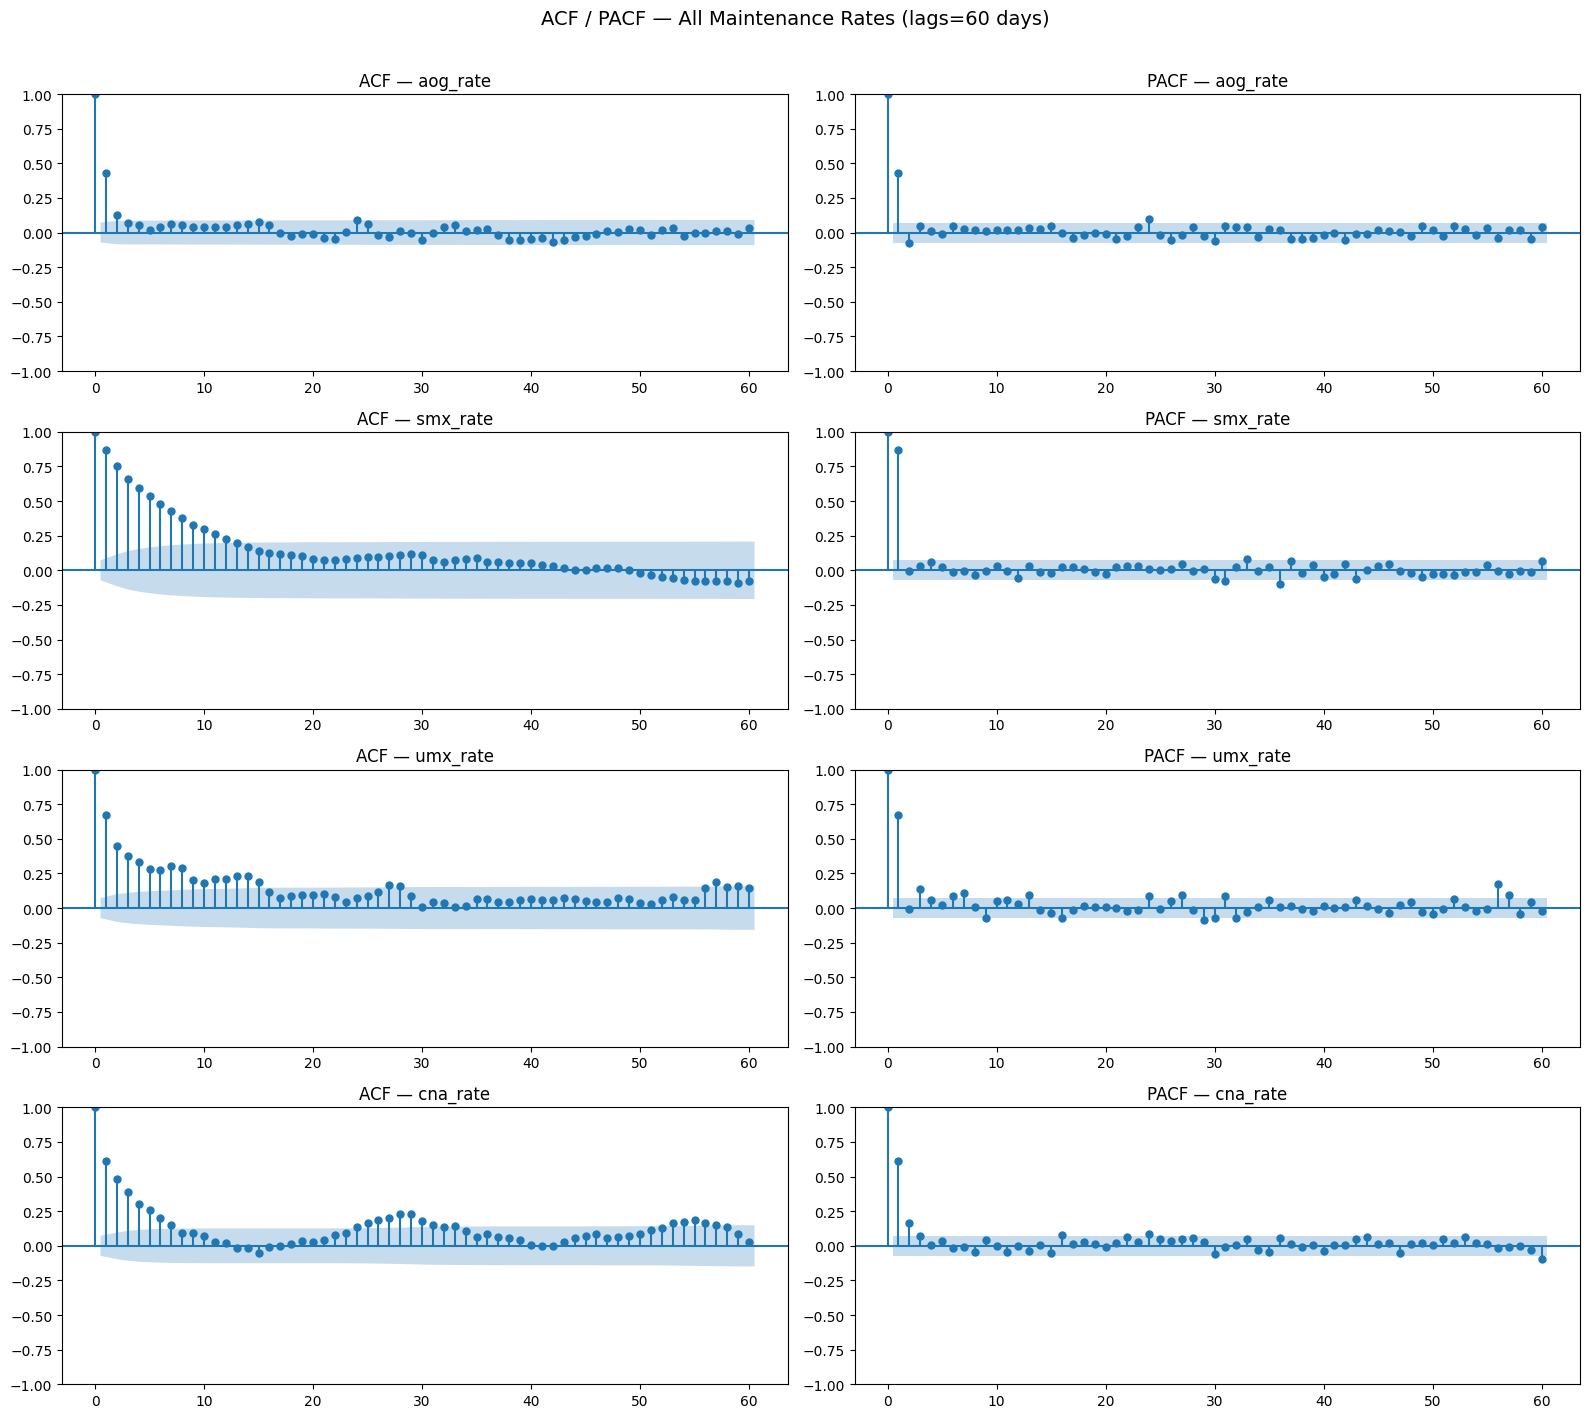

In [11]:
import matplotlib.pyplot as plt  # ACF/PACF plots use matplotlib
fig, axes = plt.subplots(4, 2, figsize=(16, 14))

for idx, col in enumerate(rate_cols):
    series = df_pd[col].dropna()
    sm.graphics.tsa.plot_acf(series, lags=60, ax=axes[idx, 0],
                              title=f"ACF — {col}")
    sm.graphics.tsa.plot_pacf(series, lags=60, ax=axes[idx, 1],
                               title=f"PACF — {col}")

plt.suptitle("ACF / PACF — All Maintenance Rates (lags=60 days)", 
             fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig("../notebooks/acf_pacf_availability.png", dpi=150, bbox_inches="tight")
plt.show()

In [12]:
corr = df_pd[rate_cols].corr()

fig = px.imshow(
    corr,
    text_auto=".2f",
    color_continuous_scale="RdBu_r",
    zmin=-1, zmax=1,
    title="Correlation Between Maintenance Rates"
)
fig.update_layout(**PLOT_CFG)
fig.show()

In [13]:
import polars as pl
from pathlib import Path

PROCESSED_DIR = Path("../data/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# save the full 2024-2025 aggregated fleet table
df_fleet.write_parquet(PROCESSED_DIR / "avl_fleet_daily.parquet")

# verify the write
df_verify = pl.read_parquet(PROCESSED_DIR / "avl_fleet_daily.parquet")
print(f"Saved shape:  {df_fleet.shape}")
print(f"Loaded shape: {df_verify.shape}")
print(f"Date range:   {df_verify['DATE_DAY'].min()} → {df_verify['DATE_DAY'].max()}")
print(f"Columns: {df_verify.columns}")

Saved shape:  (731, 19)
Loaded shape: (731, 19)
Date range:   2024-01-01 → 2025-12-31
Columns: ['DATE_DAY', 'num_tails', 'aog_count', 'smx_count', 'umx_count', 'cna_count', 'total_maint_count', 'delivered_count', 'aog_rate', 'smx_rate', 'umx_rate', 'cna_rate', 'total_maint_rate', 'avail_rate', 'day_of_week', 'month', 'quarter', 'day_of_year', 'year']
